# 11 — NASA CMR granule manifest inspection

This notebook inspects the metadata-only manifest generated by `src.firewatch.cmr_manifest`. It verifies the saved query metadata, summarizes platform/collection coverage, identifies multiple processing versions per acquisition, and plots daily granule availability. It does not download any science granules.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'data').exists() and (ROOT.parent/'data').exists(): ROOT=ROOT.parent
CSV=ROOT/'data'/'reference'/'cmr_manifest_2025-10.csv'
META=CSV.with_suffix('.metadata.json')
assert CSV.is_file() and META.is_file(), 'Run the CMR manifest command first.'
metadata=json.loads(META.read_text(encoding='utf-8'))
manifest=pd.read_csv(CSV)
manifest['time_start_utc']=pd.to_datetime(manifest.time_start_utc,utc=True)
manifest['acquisition_day']=manifest.time_start_utc.dt.strftime('%Y-%m-%d')
print('Query window:',metadata['query_start_utc'],'to',metadata['query_end_utc'],'UTC')
print('Bounding box (west,south,east,north):',metadata['query_bbox_wsen'])
print('CMR entries:',metadata['result_entries'],'| granules downloaded:',metadata['granule_files_downloaded'])


Query window: 2025-10-01 to 2025-10-31 UTC
Bounding box (west,south,east,north): 8,1,17,14
CMR entries: 759 | granules downloaded: 0


In [2]:
summary=(manifest.groupby(['platform','short_name','collection_version'])
 .agg(cmr_entries=('cmr_entry_id','size'),unique_acquisitions=('acquisition_id','nunique'),
      processing_variants=('acquisition_id',lambda s:len(s)-s.nunique()),
      direct_data_links=('data_url',lambda s:int(s.notna().sum())),
      browse_links=('browse_url',lambda s:int(s.notna().sum())),
      median_reported_size_mb=('granule_size_cmr_mb','median'))
 .reset_index().sort_values('platform'))
display(summary.round(3))
# Preserve all processing variants in the manifest; show acquisitions represented more than once.
variant_counts=manifest.groupby(['platform','acquisition_id']).size().rename('cmr_entries').reset_index()
display(variant_counts.loc[variant_counts.cmr_entries.gt(1)].sort_values(['platform','acquisition_id']))


,platform,short_name,collection_version,cmr_entries,unique_acquisitions,processing_variants,direct_data_links,browse_links,median_reported_size_mb
0,Aqua,MYD14,61,142,142,0,142,142,0.273
1,N20,VJ114IMG,2,158,158,0,158,158,1.656
2,N21,VJ214IMG,2,172,160,12,172,172,1.724
3,SNPP,VNP14IMG,2,165,165,0,165,165,1.813
4,Terra,MOD14,61,122,122,0,122,122,0.246


,platform,acquisition_id,cmr_entries
300,N21,VJ214IMG.A2025274.0048.002,4
301,N21,VJ214IMG.A2025274.0054.002,4
302,N21,VJ214IMG.A2025274.1154.002,4
303,N21,VJ214IMG.A2025274.1336.002,4


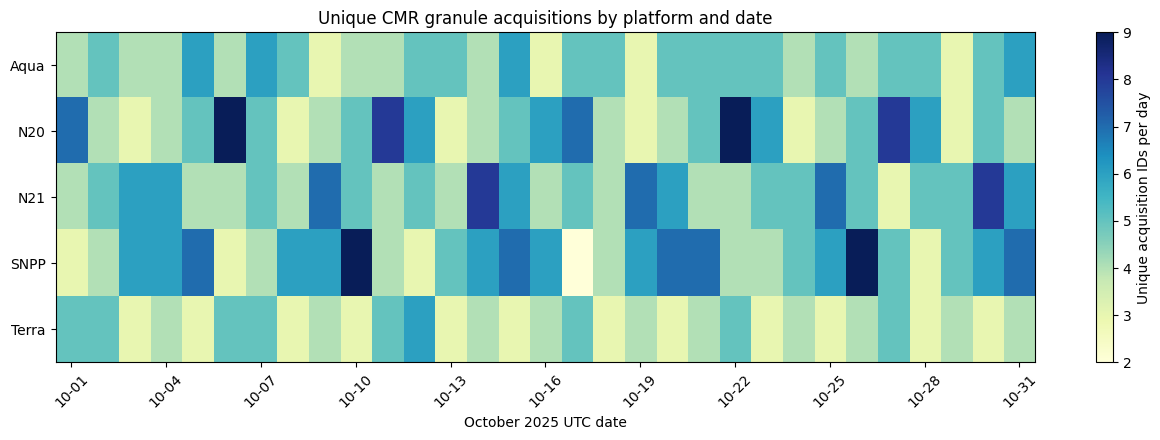

In [3]:
unique_acquisitions=manifest.drop_duplicates(['platform','acquisition_id'])
daily=(unique_acquisitions.groupby(['platform','acquisition_day']).size().unstack(fill_value=0))
date_axis=pd.date_range(metadata['query_start_utc'],metadata['query_end_utc'],freq='D').strftime('%Y-%m-%d')
daily=daily.reindex(columns=date_axis,fill_value=0)
fig,ax=plt.subplots(figsize=(13,4.5))
im=ax.imshow(daily.to_numpy(),aspect='auto',interpolation='nearest',cmap='YlGnBu')
ax.set_yticks(range(len(daily.index)),daily.index)
ticks=list(range(0,len(date_axis),3)); ax.set_xticks(ticks,[date_axis[i][5:] for i in ticks],rotation=45)
ax.set_xlabel('October 2025 UTC date'); ax.set_title('Unique CMR granule acquisitions by platform and date')
fig.colorbar(im,ax=ax,label='Unique acquisition IDs per day'); fig.tight_layout(); plt.show()


## Interpretation

A CMR row confirms a catalog granule whose metadata time/spatial extent intersects the query. It does not reveal which individual pixels were validly observed over Cameroon. The NOAA-21 collection includes multiple processing variants for some acquisitions; preserve each producer granule ID and processing timestamp in lineage and choose a consistent processing policy before analysis.

The direct science-data URLs point to NASA protected product storage. This manifest records access links only; downloading requires the appropriate Earthdata access/authentication. Browse-image URLs are separate and are not substitutes for Level-2 fire-mask/QA arrays.
